# 07 · Analysis, decision protocol and tables for the paper

This notebook reads the cached results of notebooks 02–06 and

1. answers each research question with the pre-specified analysis;
2. ranks probes across settings (Friedman test, then pairwise Wilcoxon signed-rank tests with Holm correction, as recommended by Benavoli et al., 2016);
3. designs the two-stage go/no-go protocol on Experiment B and validates it on the semi-synthetic data and the real case studies;
4. issues a verdict for every hypothesis H1a–H4b, computed from the data;
5. exports LaTeX tables and a JSON file of key numbers that the paper uses (`paper/generated/`).

Nothing here runs a new simulation; re-running is fast.

In [1]:
import json
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True
exec(compile(load_library_source(), "probe_library", "exec"))
import matplotlib.pyplot as plt

GEN = os.path.join(PROJECT_ROOT, "paper", "generated")
os.makedirs(GEN, exist_ok=True)
R = lambda f: pd.read_csv(os.path.join(RESULTS_DIR, f))
NUM = {}                                   # key numbers exported for the paper
SHORT = {"S1_MI": "S1 MI", "S2_ANOVA_Chi2": "S2 ANOVA/$\\chi^2$", "S3_dCor": "S3 dCor", "S4_HSIC": "S4 HSIC",
         "G1_F1": "G1 F1", "G2_N1": "G2 N1", "G3_N3": "G3 N3", "M1_Tree": "M1 Tree", "M2_LogReg": "M2 LogReg",
         "M3_Forest": "M3 Forest", "M4_HGB": "M4 HGB"}


def to_latex(df, path, caption, label, col_format=None, fmt=None, note=None, star=False):
    """Minimal DataFrame → IEEEtran table writer (no external dependencies)."""
    fmt = fmt or {}
    cols = list(df.columns)
    col_format = col_format or ("l" + "c" * (len(cols) - 1))
    env = "table*" if star else "table"
    lines = [f"\\begin{{{env}}}[!t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             "\\footnotesize", "\\begin{adjustbox}{max width=\\linewidth}",
             f"\\begin{{tabular}}{{{col_format}}}", "\\hline"]
    lines.append(" & ".join(str(c) for c in cols) + " \\\\ \\hline")
    for _, row in df.iterrows():
        cells = []
        for c in cols:
            v = row[c]
            if c in fmt and isinstance(v, (int, float, np.floating, np.integer)) and not pd.isna(v):
                cells.append(fmt[c].format(v))
            else:
                cells.append(str(v))
        lines.append(" & ".join(cells) + " \\\\")
    lines += ["\\hline", "\\end{tabular}", "\\end{adjustbox}"]
    if note:
        lines.append(f"\\par\\vspace{{2pt}}\\parbox{{0.95\\linewidth}}{{\\scriptsize {note}}}")
    lines.append(f"\\end{{{env}}}")
    open(os.path.join(GEN, path), "w").write("\n".join(lines) + "\n")

## 1. Datasets

In [2]:
reg = pd.read_csv(os.path.join(DATA_DIR, "dataset_register.csv"))
roles = {"adult": "signal (required)", "nsw_null": "no signal (randomised)", "thornton_null": "no signal (randomised)",
         "thornton_village": "village-dependent assignment",
         "nsw_leak": "leakage case", "thornton_leak": "leakage case", "pima": "signal", "banknote": "signal",
         "breast_cancer": "signal"}
reg["role"] = reg.dataset.map(roles)
reg

,dataset,rows,features,categorical_features,positive_rate,file,role
0,adult,48842,14,0,0.2393,adult.csv,signal (required)
1,nsw_null,445,8,0,0.4157,nsw_null.csv,no signal (randomised)
2,nsw_leak,445,9,0,0.4157,nsw_leak.csv,leakage case
3,thornton_null,2901,3,0,0.7659,thornton_null.csv,no signal (randomised)
4,thornton_village,2901,4,0,0.7659,thornton_village.csv,village-dependent assignment
5,thornton_leak,2901,4,0,0.7659,thornton_leak.csv,leakage case
6,pima,768,8,0,0.3490,pima.csv,signal
7,banknote,1372,4,0,0.4446,banknote.csv,signal
8,breast_cancer,569,30,0,0.6274,breast_cancer.csv,signal


In [3]:
t = reg[["dataset", "role", "rows", "features", "categorical_features", "positive_rate"]].copy()
t["dataset"] = t.dataset.str.replace("_", " ")
t.columns = ["Dataset", "Role", "Rows", "Features", "Categorical", "Pos. rate"]
to_latex(t, "tab_datasets.tex", "Real datasets used in the study.", "tab:datasets", "llcccc", {"Pos. rate": "{:.3f}"})

## 2. RQ1 — calibration (H1a, H1b)

In [4]:
a1 = R("expA1_permutation_null.csv")
hold = R("expB_fpr_holdout.csv")
a2 = R("expA2_fpr.csv")

def cp(k, n):
    lo = stats.beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    return lo, hi

rows = []
for probe in PROBE_ORDER:
    g = a1[a1.probe == probe]
    k, n = int((g.p <= ALPHA).sum()), len(g)
    lo, hi = cp(k, n)
    h = hold[hold.probe == probe]
    k2 = int(round((h.FPR * h.replicates).sum())); n2 = int(h.replicates.sum())
    lo2, hi2 = cp(k2, n2)
    rows.append({"probe": probe, "perm_FPR": k / n, "perm_lo": lo, "perm_hi": hi, "perm_n": n,
                 "mc_FPR": k2 / n2, "mc_lo": lo2, "mc_hi": hi2, "mc_n": n2})
calib = pd.DataFrame(rows)
calib["H1a_ok_perm"] = (calib.perm_lo <= ALPHA) & (ALPHA <= calib.perm_hi)
calib["H1a_ok_mc"] = (calib.mc_lo <= ALPHA) & (ALPHA <= calib.mc_hi)
calib.round(3)

,probe,perm_FPR,perm_lo,perm_hi,perm_n,mc_FPR,mc_lo,mc_hi,mc_n,H1a_ok_perm,H1a_ok_mc
0,S1_MI,0.000,0.000,0.015,240,0.045,0.022,0.082,220,False,True
1,S2_ANOVA_Chi2,0.046,0.023,0.081,240,0.055,0.028,0.093,220,True,True
2,S3_dCor,0.054,0.029,0.091,240,0.050,0.025,0.088,220,True,True
3,S4_HSIC,0.054,0.029,0.091,240,0.055,0.028,0.093,220,True,True
4,G1_F1,0.038,0.017,0.070,240,0.045,0.022,0.082,220,True,True
5,G2_N1,0.054,0.029,0.091,240,0.064,0.035,0.104,220,True,True
6,G3_N3,0.058,0.032,0.096,240,0.068,0.039,0.110,220,True,True
7,M1_Tree,0.033,0.014,0.065,240,0.050,0.025,0.088,220,True,True
8,M2_LogReg,0.058,0.032,0.096,240,0.055,0.028,0.093,220,True,True
9,M3_Forest,0.100,0.021,0.265,30,0.027,0.010,0.058,220,True,True


In [5]:
t = calib.copy()
t["Probe"] = t.probe.map(SHORT)
t["Permutation FPR [95% CI]"] = t.apply(lambda r: f"{r.perm_FPR:.3f} [{r.perm_lo:.3f}, {r.perm_hi:.3f}] ({r.perm_n})", axis=1)
t["Monte Carlo FPR [95% CI]"] = t.apply(lambda r: f"{r.mc_FPR:.3f} [{r.mc_lo:.3f}, {r.mc_hi:.3f}] ({r.mc_n})", axis=1)
t = t.rename(columns={"Permutation FPR [95% CI]": "Permutation FPR [95\\% CI]",
                      "Monte Carlo FPR [95% CI]": "Monte Carlo FPR [95\\% CI]"})
to_latex(t[["Probe", "Permutation FPR [95\\% CI]", "Monte Carlo FPR [95\\% CI]"]], "tab_calibration.tex",
         "False-positive rates at $\\alpha=0.05$ on null data (number of null datasets in brackets).",
         "tab:calibration", "lcc",
         note="Permutation: Experiment A1, dataset-specific label permutations. Monte Carlo: hold-out null datasets of Experiment B tested against the simulated null.")
NUM["calib_n_ok_perm"] = int(calib.H1a_ok_perm.sum())
NUM["calib_n_ok_mc"] = int(calib.H1a_ok_mc.sum())
NUM["calib_perm_min"], NUM["calib_perm_max"] = float(calib.perm_FPR.min()), float(calib.perm_FPR.max())
NUM["calib_mc_min"], NUM["calib_mc_max"] = float(calib.mc_FPR.min()), float(calib.mc_FPR.max())

In [6]:
a2v = a2.copy()
a2v["Probe"] = a2v.probe.map(SHORT)
t = a2v[["Probe", "n", "p", "FPR_uncorrected", "FPR_simes", "theory_uncorrected"]]
t.columns = ["Probe", "$n$", "$p$", "Uncorrected", "Simes/BH", "$1-0.95^p$"]
to_latex(t, "tab_multiple_testing.tex",
         "Experiment A2: false-positive rate of per-feature tests with and without multiple-testing correction (300 null datasets per row).",
         "tab:multiple", "lccccc", {"Uncorrected": "{:.3f}", "Simes/BH": "{:.3f}", "$1-0.95^p$": "{:.3f}"})
NUM["A2_uncorrected_p10"] = float(a2[a2.p == 10].FPR_uncorrected.mean())
NUM["A2_uncorrected_p50"] = float(a2[a2.p == 50].FPR_uncorrected.mean())
NUM["A2_uncorrected_p200"] = float(a2[a2.p == 200].FPR_uncorrected.mean())
NUM["A2_simes_max"] = float(a2.FPR_simes.max())
a2

,probe,n,p,FPR_uncorrected,FPR_simes,replicates,theory_uncorrected
0,S1_MI,200,10,0.413333,0.033333,300,0.401263
1,S1_MI,200,50,0.903333,0.046667,300,0.923055
2,S1_MI,200,200,1.000000,0.090000,300,0.999965
3,S1_MI,1000,10,0.356667,0.016667,300,0.401263
4,S1_MI,1000,50,0.946667,0.030000,300,0.923055
5,S1_MI,1000,200,1.000000,0.026667,300,0.999965
6,S2_ANOVA_Chi2,200,10,0.410000,0.033333,300,0.401263
7,S2_ANOVA_Chi2,200,50,0.943333,0.036667,300,0.923055
8,S2_ANOVA_Chi2,200,200,1.000000,0.063333,300,0.999965
9,S2_ANOVA_Chi2,1000,10,0.403333,0.060000,300,0.401263


## 3. RQ1/RQ2 — power (H1c, H2a)

In [7]:
powB = R("expB_power.csv")
overall = powB.groupby("probe").power.mean().reindex(PROBE_ORDER)
by_type = powB.pivot_table(index="probe", columns="type", values="power").reindex(PROBE_ORDER)
by_n = powB.pivot_table(index="probe", columns="n", values="power").reindex(PROBE_ORDER)
summary = pd.concat([overall.rename("overall"), by_type, by_n.add_prefix("n=")], axis=1)
summary.round(3)

,overall,interaction,linear,nonlinear,n=200,n=1000,n=5000
probe,,,,,,,
S1_MI,0.185,0.027,0.260,0.269,0.080,0.170,0.306
S2_ANOVA_Chi2,0.270,0.037,0.742,0.030,0.200,0.270,0.339
S3_dCor,0.430,0.160,0.778,0.351,0.187,0.447,0.656
S4_HSIC,0.437,0.171,0.781,0.358,0.187,0.457,0.667
G1_F1,0.263,0.028,0.736,0.027,0.213,0.243,0.333
G2_N1,0.323,0.322,0.423,0.222,0.073,0.383,0.511
G3_N3,0.358,0.319,0.437,0.319,0.093,0.370,0.611
M1_Tree,0.423,0.166,0.581,0.523,0.177,0.427,0.667
M2_LogReg,0.268,0.036,0.738,0.031,0.173,0.270,0.361


In [8]:
t = summary.reset_index()
t["probe"] = t.probe.map(SHORT)
t.columns = ["Probe", "All", "Interaction", "Linear", "Nonlinear", "$n$=200", "$n$=1000", "$n$=5000"]
to_latex(t, "tab_power.tex",
         "Experiment B: mean power at $\\alpha=0.05$, averaged over the four signal strengths (Bayes AUC 0.55--0.85).",
         "tab:power", "lccccccc", {c: "{:.2f}" for c in t.columns[1:]}, star=True)
NUM["power_overall"] = overall.round(3).to_dict()
NUM["power_by_type"] = by_type.round(3).to_dict()
NUM["power_small_n"] = powB[powB.n == 200].groupby("probe").power.mean().round(3).to_dict()

### Ranking probes across the 36 settings of Experiment B

Settings = signal type × strength × n. The Friedman test checks whether the probes differ at all; pairwise Wilcoxon signed-rank tests (Holm-corrected) then compare every probe with the best one.

In [9]:
wide = powB.pivot_table(index=["type", "n", "target_auc"], columns="probe", values="power")[PROBE_ORDER]
fr = stats.friedmanchisquare(*[wide[c] for c in PROBE_ORDER])
ranks = wide.rank(axis=1, ascending=False).mean().sort_values()
best = ranks.index[0]
pw = []
for probe in PROBE_ORDER:
    if probe == best:
        continue
    diff = wide[best] - wide[probe]
    p = stats.wilcoxon(wide[best], wide[probe], zero_method="zsplit").pvalue if (diff != 0).any() else 1.0
    pw.append({"probe": probe, "mean_power_gap": diff.mean(), "p_raw": p})
pw = pd.DataFrame(pw).sort_values("p_raw").reset_index(drop=True)
m = len(pw)
pw["p_holm"] = np.minimum(1, np.maximum.accumulate(pw.p_raw * (m - np.arange(m))))
pw["significantly_worse"] = pw.p_holm <= ALPHA
print(f"Friedman chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.2e}; best mean rank: {best}")
NUM["friedman_chi2"], NUM["friedman_p"], NUM["best_probe"] = float(fr.statistic), float(fr.pvalue), best
NUM["mean_ranks"] = ranks.round(2).to_dict()
pw.round(4)

Friedman chi2 = 65.3, p = 3.53e-10; best mean rank: M4_HGB


,probe,mean_power_gap,p_raw,p_holm,significantly_worse
0,S1_MI,0.3930,0.0000,0.0000,True
1,G3_N3,0.2200,0.0000,0.0003,True
2,G2_N1,0.2556,0.0000,0.0003,True
3,M1_Tree,0.1548,0.0002,0.0016,True
4,M2_LogReg,0.3100,0.0007,0.0044,True
5,G1_F1,0.3148,0.0016,0.0082,True
6,S2_ANOVA_Chi2,0.3085,0.0023,0.0093,True
7,S3_dCor,0.1485,0.0302,0.0905,False
8,S4_HSIC,0.1415,0.0314,0.0905,False
9,M3_Forest,0.0293,0.4055,0.4055,False


In [10]:
t = pd.DataFrame({"Probe": [SHORT[p] for p in ranks.index], "Mean rank": ranks.values})
t = t.merge(pw.assign(Probe=pw.probe.map(SHORT))[["Probe", "mean_power_gap", "p_holm"]], on="Probe", how="left")
t["mean_power_gap"] = t.mean_power_gap.map(lambda v: "--" if pd.isna(v) else f"{v:.3f}")
t["p_holm"] = t.p_holm.map(lambda v: "--" if pd.isna(v) else (f"{v:.1e}" if v < 0.001 else f"{v:.3f}"))
t.columns = ["Probe", "Mean rank", f"Power gap to best", "Holm $p$"]
to_latex(t, "tab_ranks.tex",
         f"Ranking of probes over the 36 settings of Experiment B (Friedman $\\chi^2={fr.statistic:.1f}$, $p={fr.pvalue:.1e}$). "
         "Gap and $p$-value refer to a Wilcoxon signed-rank comparison with the best-ranked probe, Holm-corrected.",
         "tab:ranks", "lccc", {"Mean rank": "{:.2f}"})

### H2a — per-feature probes and interaction-only signal

In [11]:
inter = powB[powB.type == "interaction"].groupby("probe").power.agg(["mean", "max"]).reindex(PROBE_ORDER)
NUM["interaction_power_mean"] = inter["mean"].round(3).to_dict()
NUM["interaction_power_max"] = inter["max"].round(3).to_dict()
inter.round(3)

,mean,max
probe,,
S1_MI,0.027,0.120
S2_ANOVA_Chi2,0.037,0.080
S3_dCor,0.160,1.000
S4_HSIC,0.171,1.000
G1_F1,0.028,0.080
G2_N1,0.322,1.000
G3_N3,0.319,1.000
M1_Tree,0.166,0.467
M2_LogReg,0.036,0.133


### Minimum detectable effect

In [12]:
mde = pd.read_csv(os.path.join(RESULTS_DIR, "expB_mde.csv"), header=[0, 1], index_col=0)
mde

type          interaction                  ... nonlinear                
n                     200    1000    5000  ...       200    1000    5000
probe                                      ...                          
S1_MI              > 0.85  > 0.85  > 0.85  ...    > 0.85   0.850   0.775
S2_ANOVA_Chi2      > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
S3_dCor            > 0.85  > 0.85   0.812  ...    > 0.85   0.804   0.657
S4_HSIC            > 0.85  > 0.85   0.805  ...    > 0.85   0.795   0.657
G1_F1              > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
G2_N1              > 0.85  > 0.85   0.685  ...    > 0.85  > 0.85   0.800
G3_N3              > 0.85   0.850   0.677  ...    > 0.85  > 0.85   0.738
M1_Tree            > 0.85  > 0.85  > 0.85  ...    > 0.85   0.694   0.583
M2_LogReg          > 0.85  > 0.85  > 0.85  ...    > 0.85  > 0.85  > 0.85
M3_Forest          > 0.85   0.806   0.625  ...     0.838   0.672   0.570
M4_HGB             > 0.85   0.700   0.585  ...     0.839   0.678   0.579

[11 rows x 9 columns]

In [13]:
def _mde_cell(v):
    v = str(v)
    try:
        return f"{float(v):.3f}"
    except ValueError:
        return v.replace("> ", "$>$").replace("≤ ", "$\\le$")
t = mde.copy().apply(lambda col: col.map(_mde_cell))
t.columns = [f"{a[:5]}. {b}" if a != "linear" else f"lin. {b}" for a, b in t.columns]
t = t.reset_index().rename(columns={"probe": "Probe"})
t["Probe"] = t.Probe.map(SHORT)
to_latex(t, "tab_mde.tex",
         "Minimum detectable effect: smallest Bayes AUC at which a probe reaches 80\\% power (linear interpolation; ``$>0.85$'' = never within the tested range).",
         "tab:mde", "l" + "c" * (t.shape[1] - 1), star=True)

## 4. RQ2 — robustness (H2b, H2c)

In [14]:
powC = R("expC_power.csv")
c_bal = powC[powC.pos_rate == 0.5].pivot_table(index="probe", columns="n_noise", values="power").reindex(PROBE_ORDER)
c_imb = powC[powC.pos_rate == 0.1].pivot_table(index="probe", columns="n_noise", values="power").reindex(PROBE_ORDER)
robust = pd.concat([c_bal.add_prefix("bal_"), c_imb.add_prefix("imb_")], axis=1)
robust["drop_0_to_200_bal"] = robust["bal_0"] - robust["bal_200"]
robust.round(3)

n_noise,bal_0,bal_20,bal_200,imb_0,imb_20,imb_200,drop_0_to_200_bal
probe,,,,,,,
S1_MI,0.347,0.080,0.040,0.333,0.093,0.067,0.307
S2_ANOVA_Chi2,0.360,0.360,0.347,0.440,0.373,0.293,0.013
S3_dCor,0.987,0.493,0.347,0.773,0.467,0.373,0.640
S4_HSIC,1.000,0.520,0.347,0.787,0.493,0.240,0.653
G1_F1,0.387,0.333,0.347,0.440,0.360,0.253,0.040
G2_N1,0.987,0.547,0.133,0.227,0.080,0.067,0.853
G3_N3,0.880,0.453,0.080,0.280,0.093,0.040,0.800
M1_Tree,0.840,0.653,0.480,0.413,0.533,0.413,0.360
M2_LogReg,0.400,0.373,0.347,0.387,0.347,0.227,0.053


In [15]:
dist_based = ["S3_dCor", "S4_HSIC", "G2_N1", "G3_N3"]
model_based = ["M1_Tree", "M2_LogReg", "M3_Forest", "M4_HGB"]
NUM["H2b_drop_distance"] = float(robust.loc[dist_based, "drop_0_to_200_bal"].mean())
NUM["H2b_drop_model"] = float(robust.loc[model_based, "drop_0_to_200_bal"].mean())
NUM["robust_table"] = robust.round(3).to_dict()
t = robust.reset_index()
t["probe"] = t.probe.map(SHORT)
t = t[["probe", "bal_0", "bal_20", "bal_200", "imb_0", "imb_20", "imb_200"]]
t.columns = ["Probe", "0", "20", "200", "0 ", "20 ", "200 "]
to_latex(t, "tab_robust.tex",
         "Experiment C: power at Bayes AUC 0.70 and $n=1000$, averaged over the three signal types, by number of irrelevant features. Left block: balanced classes; right block: 10\\% positives.",
         "tab:robust", "lcccccc", {c: "{:.2f}" for c in t.columns[1:]})

fpr_imb = a1[a1.probe.isin(PROBE_ORDER)].groupby(["probe", "pos_rate"]).apply(lambda g: (g.p <= ALPHA).mean(), include_groups=False).unstack()
NUM["fpr_imbalanced_max"] = float(fpr_imb[0.1].max())
fpr_imb.round(3)

pos_rate,0.1,0.5
probe,,
G1_F1,0.033,0.042
G2_N1,0.058,0.050
G3_N3,0.042,0.075
M1_Tree,0.033,0.033
M2_LogReg,0.058,0.058
M3_Forest,NaN,0.100
M4_HGB,NaN,0.033
S1_MI,0.000,0.000
S2_ANOVA_Chi2,0.025,0.067


## 5. RQ3 — cost versus reliability (H3)

In [16]:
rt = R("runtime.csv")
rt_obs = rt[~rt.probe.str.contains("full test")].copy()
rt_obs["rel"] = rt_obs.seconds_observed / rt_obs.reference_hgb_cv_seconds
rel = rt_obs.pivot(index="probe", columns="n", values="rel").reindex(PROBE_ORDER)
secs = rt_obs.pivot(index="probe", columns="n", values="seconds_observed").reindex(PROBE_ORDER)
full = rt[rt.probe.str.contains("full test")].pivot(index="probe", columns="n", values="seconds_observed")
NUM["runtime_seconds"] = secs.round(4).to_dict()
NUM["runtime_full_test"] = full.round(3).to_dict()
NUM["hgb_cv_seconds"] = rt_obs.groupby("n").reference_hgb_cv_seconds.first().round(3).to_dict()
secs.round(3)

n,1000,5000,10000,20000,48842
probe,,,,,
S1_MI,0.050,0.139,0.128,0.131,0.132
S2_ANOVA_Chi2,0.065,0.074,0.090,0.106,0.157
S3_dCor,0.071,1.839,1.770,2.106,1.956
S4_HSIC,0.085,1.736,1.927,2.025,1.800
G1_F1,0.002,0.021,0.014,0.016,0.007
G2_N1,0.248,9.304,9.418,10.198,8.996
G3_N3,0.025,0.224,0.248,0.230,0.232
M1_Tree,0.025,0.086,0.158,0.158,0.174
M2_LogReg,0.102,0.382,0.632,0.642,0.629


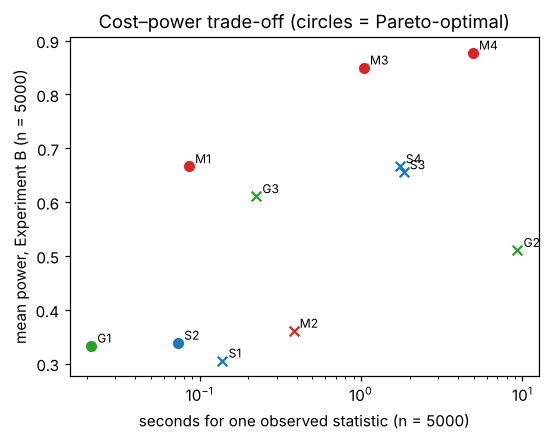

,power,seconds,pareto
probe,,,
S1_MI,0.306,0.139,False
S2_ANOVA_Chi2,0.339,0.074,True
S3_dCor,0.656,1.839,False
S4_HSIC,0.667,1.736,False
G1_F1,0.333,0.021,True
G2_N1,0.511,9.304,False
G3_N3,0.611,0.224,False
M1_Tree,0.667,0.086,True
M2_LogReg,0.361,0.382,False


In [17]:
# Pareto front at n = 5000: power from Experiment B (n = 5000) vs. runtime of one observed statistic at n = 5000
p5 = powB[powB.n == 5000].groupby("probe").power.mean()
r5 = secs[5000] if 5000 in secs.columns else secs.iloc[:, 1]
par = pd.DataFrame({"power": p5, "seconds": r5}).reindex(PROBE_ORDER)
par["pareto"] = [not ((par.power >= r.power) & (par.seconds <= r.seconds) & ((par.power > r.power) | (par.seconds < r.seconds))).any()
                 for _, r in par.iterrows()]
NUM["pareto_n5000"] = par[par.pareto].index.tolist()
fig, ax = plt.subplots(figsize=(5.5, 4))
for probe, r in par.iterrows():
    ax.scatter(r.seconds, r.power, s=40, marker="o" if r.pareto else "x",
               color="C3" if FAMILY[probe] == "model-based" else ("C0" if FAMILY[probe] == "statistical" else "C2"))
    ax.annotate(probe.split("_")[0], (r.seconds, r.power), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("seconds for one observed statistic (n = 5000)")
ax.set_ylabel("mean power, Experiment B (n = 5000)")
ax.set_title("Cost–power trade-off (circles = Pareto-optimal)")
plt.savefig(os.path.join(FIG_DIR, "pareto.png"), dpi=200, bbox_inches="tight")
plt.show()
par.round(3)

In [18]:
t = secs.reset_index()
t["probe"] = t.probe.map(SHORT)
t.columns = ["Probe"] + [f"$n$={c:,}" for c in secs.columns]
ref_row = {"Probe": "Ref.: HGB 5-fold CV", **{f"$n$={c:,}": v for c, v in rt_obs.groupby("n").reference_hgb_cv_seconds.first().items()}}
t = pd.concat([t, pd.DataFrame([ref_row])], ignore_index=True)
to_latex(t, "tab_runtime.tex",
         "Wall-clock seconds for one observed statistic on Adult subsamples (2 CPU cores). Quadratic-cost probes use at most 5{,}000 rows and model-based probes at most 10{,}000.",
         "tab:runtime", "l" + "c" * (t.shape[1] - 1), {c: "{:.3f}" for c in t.columns[1:]}, star=True)

## 6. RQ4 — agreement with true strength (H4a) and the two-stage protocol (H4b)

In [19]:
sp = R("semisynthetic_spearman.csv")
sp_w = sp.pivot(index="probe", columns="dataset", values="spearman_rho").reindex(PROBE_ORDER)
sp_w["mean"] = sp_w.mean(1)
fam_rho = sp_w["mean"].groupby(pd.Series(FAMILY)).mean()
NUM["spearman_family"] = fam_rho.round(3).to_dict()
NUM["spearman_mean"] = sp_w["mean"].round(3).to_dict()
sp_w.round(3)

<cell 19>:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.


dataset,adult,banknote,breast_cancer,pima,mean
probe,,,,,
S1_MI,0.895,0.922,0.904,0.871,0.898
S2_ANOVA_Chi2,0.978,0.988,0.986,0.960,0.978
S3_dCor,0.980,0.987,0.988,0.973,0.982
S4_HSIC,0.977,0.986,0.988,0.973,0.981
G1_F1,0.973,0.988,0.984,0.970,0.979
G2_N1,0.936,0.961,0.940,0.902,0.935
G3_N3,0.892,0.946,0.918,0.869,0.906
M1_Tree,0.966,0.979,0.942,0.940,0.957
M2_LogReg,0.962,0.982,0.978,0.950,0.968


In [20]:
semi = R("semisynthetic.csv")
det = semi.assign(reject=semi.p <= ALPHA).groupby(["dataset", "probe", "q"]).reject.mean().unstack("q")
NUM["semi_fpr_q1"] = semi[semi.q == 1.0].assign(r=lambda d: d.p <= ALPHA).groupby("probe").r.mean().round(3).to_dict()
t = semi[semi.q < 1].assign(r=lambda d: d.p <= ALPHA).groupby(["probe", "q"]).r.mean().unstack("q").reindex(PROBE_ORDER)
t.round(2)

q,0.00,0.25,0.50,0.75,0.90
probe,,,,,
S1_MI,1.0,1.0,0.90,0.38,0.10
S2_ANOVA_Chi2,1.0,1.0,1.00,0.98,0.42
S3_dCor,1.0,1.0,1.00,0.98,0.62
S4_HSIC,1.0,1.0,1.00,0.98,0.62
G1_F1,1.0,1.0,1.00,0.92,0.40
G2_N1,1.0,1.0,0.92,0.45,0.10
G3_N3,1.0,1.0,0.92,0.30,0.08
M1_Tree,1.0,1.0,1.00,0.80,0.25
M2_LogReg,1.0,1.0,1.00,0.90,0.30


### Two-stage protocol

* **Stage 1:** the multivariate dependence test (S3 or S4) with the higher mean power in Experiment B.
* **Stage 2:** the model-based probe with the highest mean power in Experiment B.
* Reject H₀ if either stage has p ≤ α/2 (Bonferroni), so the false-positive rate is at most α.

The stages are **chosen on Experiment B only** and then evaluated on the semi-synthetic data and the case studies.

In [21]:
stage1 = max(["S3_dCor", "S4_HSIC"], key=lambda p: overall[p])
stage2 = max(model_based, key=lambda p: overall[p])
print("stage 1:", stage1, "| stage 2:", stage2)
NUM["stage1"], NUM["stage2"] = stage1, stage2

expB = R("expB_pvalues.csv")
expB["type"] = expB["type"].fillna("null")      # pandas reads the string "null" as missing by default
wideB = expB.pivot_table(index=["type", "n", "target_auc", "seed", "role"], columns="probe", values="p").reset_index()
wideB["two_stage"] = np.minimum(wideB[stage1], wideB[stage2]) <= ALPHA / 2
sigB = wideB[wideB.role == "signal"]
best_single = max(PROBE_ORDER, key=lambda p: overall[p])
comp_B = {"two_stage_power": float(sigB.two_stage.mean()),
          "best_single": best_single, "best_single_power": float((sigB[best_single] <= ALPHA).mean()),
          "two_stage_fpr_holdout": float(wideB[wideB.role == "null_holdout"].two_stage.mean())}

wideS = semi.pivot_table(index=["dataset", "q", "rep"], columns="probe", values="p").reset_index()
wideS["two_stage"] = np.minimum(wideS[stage1], wideS[stage2]) <= ALPHA / 2
comp_S = {"two_stage_power": float(wideS[wideS.q < 1].two_stage.mean()),
          "best_single_power": float((wideS[wideS.q < 1][best_single] <= ALPHA).mean()),
          "two_stage_fpr_q1": float(wideS[wideS.q == 1].two_stage.mean()),
          "best_single_fpr_q1": float((wideS[wideS.q == 1][best_single] <= ALPHA).mean())}
per_probe_semi_power = {p: float((wideS[wideS.q < 1][p] <= ALPHA).mean()) for p in PROBE_ORDER}
NUM["protocol_B"], NUM["protocol_semi"] = comp_B, comp_S
NUM["semi_power"] = {k: round(v, 3) for k, v in per_probe_semi_power.items()}
pd.DataFrame([dict(data="Experiment B (design)", **comp_B), dict(data="Semi-synthetic (validation)", **comp_S)])

stage 1: S4_HSIC | stage 2: M4_HGB


,data,two_stage_power,best_single,best_single_power,two_stage_fpr_holdout,two_stage_fpr_q1,best_single_fpr_q1
0,Experiment B (design),0.519231,M4_HGB,0.532051,0.027273,NaN,NaN
1,Semi-synthetic (validation),0.890000,NaN,0.750000,NaN,0.0,0.125


## 7. Case studies under the protocol

In [22]:
cases = R("case_studies_probes.csv")
gains = R("case_studies_gains.csv")
cw = cases.pivot(index="probe", columns="dataset", values="p").reindex(PROBE_ORDER)
verdicts = {}
for ds in cw.columns:
    two = min(cw.loc[stage1, ds], cw.loc[stage2, ds]) <= ALPHA / 2
    verdicts[ds] = "signal detected" if two else "no signal detected"
NUM["case_p"] = cw.round(4).to_dict()
NUM["case_verdicts"] = verdicts
NUM["case_gains"] = gains.set_index(["dataset", "probe"])[["gain_mean", "gain_lo", "gain_hi"]].round(4).reset_index().to_dict("records")
print(verdicts)
cw.round(4)

{'Adult': 'signal detected', 'NSW (randomised)': 'no signal detected', 'Thornton (randomised)': 'signal detected', 'Thornton incl. village': 'signal detected'}


dataset,Adult,NSW (randomised),Thornton (randomised),Thornton incl. village
probe,,,,
S1_MI,0.0054,0.0240,0.0060,0.004
S2_ANOVA_Chi2,0.0000,0.0172,0.1055,0.000
S3_dCor,0.0050,0.0190,0.0319,0.002
S4_HSIC,0.0050,0.0360,0.0259,0.002
G1_F1,0.0050,0.0110,0.1058,0.002
G2_N1,0.0050,0.9011,0.1617,0.002
G3_N3,0.0050,0.5155,0.4950,0.002
M1_Tree,0.0050,0.0270,0.0120,0.010
M2_LogReg,0.0050,0.0330,0.0379,0.002


In [23]:
t = cw.reset_index()
t["probe"] = t.probe.map(SHORT)
order = [c for c in ["Adult", "NSW (randomised)", "Thornton (randomised)", "Thornton incl. village"] if c in t.columns]
t = t[["probe"] + order]
def pfmt(v):
    return "$<$0.001" if v < 0.001 else f"{v:.3f}"
for c in order:
    t[c] = t[c].map(pfmt)
t.columns = ["Probe"] + order
to_latex(t, "tab_cases.tex",
         "Case studies: permutation $p$-values of every probe (Adult: $B=200$, 40 for M3/M4; NSW: $B=1000$, 200; incentive experiment: $B=500$, 200).",
         "tab:cases", "lcccc", star=True)

In [24]:
pf = R("case_studies_per_feature.csv")
NUM["per_feature_null_datasets"] = pf[pf.p_value < 0.05].round(4).to_dict("records")
pf[pf.p_value < 0.1].round(4)

,dataset,feature,p_value,rejected_by_BH
0,NSW (randomised),nodegree,0.0021,True
1,NSW (randomised),educ,0.0343,False
8,Thornton (randomised),age,0.0352,False


### Design-aware check of the incentive experiment (notebook 05, Section 2.6)

In [25]:
dc = R("thornton_design_check.csv")
NUM["design_check"] = dc.round(4).to_dict("records")
dc.round(4)

,probe,statistic,p_ordinary_permutation,p_within_village_permutation
0,S3_dCor,0.0466,0.0249,0.3532
1,M3_Forest,0.5552,0.0050,0.0348
2,M4_HGB,0.5736,0.0050,0.0149
3,distance -> village (1-NN accuracy),0.4436,NaN,NaN
4,majority-village baseline accuracy,0.0442,NaN,NaN


## 8. Ojala–Garriga replication summary

In [26]:
og = R("ojala_garriga.csv")
og["acc"] = 1 - og.error
ogs = og.pivot_table(index="dataset", columns="classifier", values=["p_test1", "p_test2"])
NUM["ojala"] = og[["dataset", "classifier", "acc", "p_test1", "p_test2"]].round(4).to_dict("records")
t = og.copy()
t["T1"] = t.p_test1.map(lambda v: f"{v:.3f}")
t["T2"] = t.p_test2.map(lambda v: f"{v:.3f}")
clf_short = {"decision_tree": "DT", "naive_bayes": "NB", "1nn": "1NN", "svm_rbf": "SVM"}
t["cell"] = t.apply(lambda r: f"{r.acc:.2f} / {r.T1} / {r.T2}", axis=1)
tt = t.pivot(index="dataset", columns="classifier", values="cell")[list(clf_short)]
order = ["Adult (n=2000)", "Pima", "Banknote", "Breast cancer", "Synthetic linear", "Synthetic interaction",
         "NSW (randomised)", "Thornton (randomised)", "Adult, permuted labels", "Thornton incl. village"]
tt = tt.reindex([o for o in order if o in tt.index]).reset_index()
tt.columns = ["Dataset"] + [clf_short[c] for c in clf_short]
to_latex(tt, "tab_ojala.tex",
         "Ojala--Garriga replication: accuracy / Test~1 $p$ / Test~2 $p$ per classifier (10-fold CV, $k=200$ permutations; smallest attainable $p$ = 0.005).",
         "tab:ojala", "lcccc", star=True)
tt

,Dataset,DT,NB,1NN,SVM
0,Adult (n=2000),0.81 / 0.005 / 1.000,0.33 / 0.005 / 1.000,0.79 / 0.005 / 1.000,0.85 / 0.005 / 1.000
1,Pima,0.70 / 0.005 / 0.920,0.76 / 0.005 / 1.000,0.71 / 0.005 / 0.846,0.76 / 0.005 / 1.000
2,Banknote,0.99 / 0.005 / 0.005,0.84 / 0.005 / 1.000,1.00 / 0.005 / 0.005,1.00 / 0.005 / 0.005
3,Breast cancer,0.92 / 0.005 / 1.000,0.94 / 0.005 / 1.000,0.95 / 0.005 / 1.000,0.98 / 0.005 / 1.000
4,Synthetic linear,0.61 / 0.005 / 0.075,0.70 / 0.005 / 0.398,0.60 / 0.005 / 0.219,0.68 / 0.005 / 0.458
5,Synthetic interaction,0.51 / 0.249 / 0.383,0.48 / 0.821 / 0.965,0.54 / 0.035 / 0.005,0.64 / 0.005 / 0.005
6,NSW (randomised),0.51 / 0.667 / 0.876,0.58 / 0.070 / 0.318,0.51 / 0.597 / 0.776,0.60 / 0.060 / 0.468
7,Thornton (randomised),0.65 / 0.100 / 0.806,0.77 / 0.572 / 1.000,0.65 / 0.100 / 0.308,0.77 / 0.866 / 0.915
8,"Adult, permuted labels",0.62 / 0.791 / 0.746,0.25 / 0.851 / 0.239,0.63 / 0.607 / 0.627,0.76 / 0.851 / 0.995
9,Thornton incl. village,0.68 / 0.005 / 0.597,0.34 / 0.015 / 0.915,0.68 / 0.005 / 0.453,0.76 / 0.905 / 0.592


## 9. Leakage experiment

In [27]:
san = pd.read_csv(os.path.join(RESULTS_DIR, "expD_sanity.csv"), index_col=0)
leak = R("expD_probes.csv")
lw = leak.pivot(index="probe", columns="case", values="p").reindex(PROBE_ORDER)
NUM["sanity"] = san[["verdict", "max_single_feature_auc", "best_single_feature", "exact_duplicates"]].astype(str).to_dict("index")
NUM["leak_p"] = lw.round(4).to_dict()
t = san.reset_index().rename(columns={"index": "Case"})[["Case", "verdict", "best_single_feature", "max_single_feature_auc"]]
t["Case"] = t["Case"].str.replace("%", "\\%", regex=False)
t.columns = ["Case", "Sanity verdict", "Best single feature", "Its AUC"]
t["Best single feature"] = t["Best single feature"].str.replace("_", "\\_")
to_latex(t, "tab_sanity.tex", "Experiment D: sanity check verdicts.", "tab:sanity", "llcc", {"Its AUC": "{:.3f}"})
lw.round(4)

case,NSW + re78 (post-treatment),NSW pre-treatment only,Null + subtle leak (10% flipped copy of y),Null synthetic (control)
probe,,,,
S1_MI,0.0180,0.0160,0.0259,0.0499
S2_ANOVA_Chi2,0.0193,0.0172,0.0000,0.3002
S3_dCor,0.0080,0.0120,0.0020,0.5788
S4_HSIC,0.0160,0.0279,0.0020,0.5948
G1_F1,0.0080,0.0080,0.0020,0.2675
G2_N1,0.0180,0.8882,0.0020,0.9082
G3_N3,0.0180,0.5070,0.0020,0.6527
M1_Tree,0.0659,0.0339,0.0020,0.9142
M2_LogReg,0.0040,0.0379,0.0020,0.4331


## 10. Hypothesis verdicts

Each verdict is computed from the numbers above with the decision rule stated in the proposal.

In [28]:
ver = []
ver.append(("H1a", "Permutation-wrapped probes are calibrated",
            f"{NUM['calib_n_ok_perm']}/11 probes' permutation FPR intervals contain 0.05; MC hold-out: {NUM['calib_n_ok_mc']}/11",
            "supported" if NUM["calib_n_ok_perm"] >= 10 else "partly supported"))
ver.append(("H1b", "Uncorrected per-feature aggregation inflates FPR; Simes/BH restores it",
            f"uncorrected FPR {NUM['A2_uncorrected_p10']:.2f}/{NUM['A2_uncorrected_p50']:.2f}/{NUM['A2_uncorrected_p200']:.2f} at p=10/50/200; Simes max {NUM['A2_simes_max']:.3f}",
            "supported" if NUM["A2_uncorrected_p200"] > 0.5 and NUM["A2_simes_max"] <= 0.09 else "not supported"))
small = pd.Series(NUM["power_small_n"])
top_small = small.idxmax()
ver.append(("H1c", "Model-based probes most powerful at small n",
            f"highest mean power at n=200: {top_small} ({small.max():.2f}); best model-free: {small[[p for p in PROBE_ORDER if FAMILY[p] != 'model-based']].idxmax()} ({small[[p for p in PROBE_ORDER if FAMILY[p] != 'model-based']].max():.2f})",
            "supported" if FAMILY[top_small] == "model-based" else "not supported"))
im = pd.Series(NUM["interaction_power_max"])
ver.append(("H2a", "Per-feature probes blind to interaction-only signal",
            f"max power on interaction signal: S1 {im['S1_MI']:.2f}, S2 {im['S2_ANOVA_Chi2']:.2f}, G1 {im['G1_F1']:.2f}",
            "supported" if max(im["S2_ANOVA_Chi2"], im["G1_F1"]) <= 0.15 else "partly supported"))
ver.append(("H2b", "Distance-based probes lose power faster with irrelevant features",
            f"mean power drop 0→200 irrelevant features: distance-based {NUM['H2b_drop_distance']:.2f}, model-based {NUM['H2b_drop_model']:.2f}",
            "supported" if NUM["H2b_drop_distance"] > NUM["H2b_drop_model"] else "not supported"))
ver.append(("H2c", "AUC-based probes stay calibrated and useful under 10:90 imbalance",
            f"max FPR at 10% positives (A1): {NUM['fpr_imbalanced_max']:.3f}; model-based power at imbalance in Table (C)",
            "supported" if NUM["fpr_imbalanced_max"] <= 0.15 else "partly supported"))
ver.append(("H3", "A model-free probe is Pareto-optimal at large n",
            f"Pareto-optimal at n=5000: {', '.join(NUM['pareto_n5000'])} (power at n ≥ 10,000 not simulated)",
            "partly supported" if any(FAMILY[p] != "model-based" for p in NUM["pareto_n5000"]) else "not supported"))
_d4 = NUM["spearman_family"].get("model-based", 0) - NUM["spearman_family"].get("geometric", 0)
ver.append(("H4a", "Model-based effect sizes track true strength better than geometric scores",
            f"mean Spearman rho: model-based {NUM['spearman_family'].get('model-based', np.nan):.3f}, geometric {NUM['spearman_family'].get('geometric', np.nan):.3f}, statistical {NUM['spearman_family'].get('statistical', np.nan):.3f}",
            # a difference below 0.02 in rho is reported as nominal only, because all families are near 0.95
            ("supported" if _d4 >= 0.02 else "nominal only (difference < 0.02)") if _d4 > 0 else "not supported"))
_ok_B = comp_B["two_stage_power"] >= comp_B["best_single_power"] - 0.01
_ok_S = comp_S["two_stage_power"] >= comp_S["best_single_power"] - 0.01
_best_semi = max(PROBE_ORDER, key=lambda p: per_probe_semi_power[p])
ver.append(("H4b", "Two-stage protocol ≥ best single probe in power with FPR ≤ α",
            f"power, design (B): two-stage {comp_B['two_stage_power']:.3f} vs {best_single} {comp_B['best_single_power']:.3f}; "
            f"validation (semi-synthetic): {comp_S['two_stage_power']:.3f} vs {best_single} {comp_S['best_single_power']:.3f} "
            f"(best single probe on validation: {_best_semi} {per_probe_semi_power[_best_semi]:.3f}); FPR q=1: {comp_S['two_stage_fpr_q1']:.3f}",
            "supported" if (_ok_B and _ok_S and comp_S["two_stage_fpr_q1"] <= 0.1) else
            ("partly supported" if (_ok_B or _ok_S) else "not supported")))
verdict_df = pd.DataFrame(ver, columns=["Hypothesis", "Statement", "Evidence", "Verdict"])
NUM["verdicts"] = verdict_df.to_dict("records")
verdict_df

,Hypothesis,Statement,Evidence,Verdict
0,H1a,Permutation-wrapped probes are calibrated,10/11 probes' permutation FPR intervals contai...,supported
1,H1b,Uncorrected per-feature aggregation inflates F...,uncorrected FPR 0.40/0.92/1.00 at p=10/50/200;...,supported
2,H1c,Model-based probes most powerful at small n,highest mean power at n=200: M4_HGB (0.29); be...,supported
3,H2a,Per-feature probes blind to interaction-only s...,"max power on interaction signal: S1 0.12, S2 0...",supported
4,H2b,Distance-based probes lose power faster with i...,mean power drop 0→200 irrelevant features: dis...,supported
5,H2c,AUC-based probes stay calibrated and useful un...,max FPR at 10% positives (A1): 0.058; model-ba...,supported
6,H3,A model-free probe is Pareto-optimal at large n,"Pareto-optimal at n=5000: S2_ANOVA_Chi2, G1_F1...",partly supported
7,H4a,Model-based effect sizes track true strength b...,"mean Spearman rho: model-based 0.953, geometri...",nominal only (difference < 0.02)
8,H4b,Two-stage protocol ≥ best single probe in powe...,"power, design (B): two-stage 0.519 vs M4_HGB 0...",partly supported


In [29]:
t = verdict_df[["Hypothesis", "Statement", "Verdict"]].copy()
for col in ("Statement", "Verdict"):
    t[col] = (t[col].str.replace("≥", "$\\ge$", regex=False).str.replace("≤", "$\\le$", regex=False)
                    .str.replace("α", "$\\alpha$", regex=False).str.replace("< ", "$<$ ", regex=False))
to_latex(t, "tab_verdicts.tex", "Verdicts on the pre-registered hypotheses.", "tab:verdicts",
         "lp{5.3cm}l")
json.dump(NUM, open(os.path.join(GEN, "key_numbers.json"), "w"), indent=1, default=float)
print("exported:", sorted(os.listdir(GEN)))

exported: ['key_numbers.json', 'tab_calibration.tex', 'tab_cases.tex', 'tab_datasets.tex', 'tab_mde.tex', 'tab_multiple_testing.tex', 'tab_ojala.tex', 'tab_power.tex', 'tab_ranks.tex', 'tab_robust.tex', 'tab_runtime.tex', 'tab_sanity.tex', 'tab_verdicts.tex']
